In [2]:
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

In [3]:
def create_dataframe():

    data={
        "points":[18,19,14,14,11,20,28,30,31,35,33,25,25,27,29,30,19,23],
        "assists":[3,4,5,4,7,8,7,6,9,12,14,9,4,3,4,12,15,11],
        "rebounds":[15,14,10,8,14,13,9,5,4,11,6,5,3,8,12,7,6,5]
    }

    df=pd.DataFrame(data)
    df.index=["P"+str(i+1) for i in range(len(df))]

    return df

df=create_dataframe()
X=df.values.astype(float)

print(df)

     points  assists  rebounds
P1       18        3        15
P2       19        4        14
P3       14        5        10
P4       14        4         8
P5       11        7        14
P6       20        8        13
P7       28        7         9
P8       30        6         5
P9       31        9         4
P10      35       12        11
P11      33       14         6
P12      25        9         5
P13      25        4         3
P14      27        3         8
P15      29        4        12
P16      30       12         7
P17      19       15         6
P18      23       11         5


# Distance functions and K-means (without scikit-learn)

In [4]:
def euclidean(a,b):
    return math.sqrt(sum((a[i]-b[i])**2 for i in range(len(a))))

def manhattan(a,b):
    return sum(abs(a[i]-b[i]) for i in range(len(a)))

def minkowski(a,b,p=3):
    return sum(abs(a[i]-b[i])**p for i in range(len(a)))**(1/p)


def initial_centroids(X,k):

    n=len(X)
    centroids=[]

    for i in range(k):
        centroids.append(list(X[int(i*n/k)]))

    return centroids


def kmeans(X,k,dist,max_iter=100):

    centroids=initial_centroids(X,k)
    history=[]

    for it in range(max_iter):

        labels=[]
        errors=[]

        for x in X:
            d=[dist(x,c) for c in centroids]
            j=d.index(min(d))
            labels.append(j)
            errors.append(d[j]**2)

        history.append(errors)

        new_centroids=[]

        for j in range(k):
            members=[X[i] for i in range(len(X)) if labels[i]==j]

            if len(members)==0:
                new_centroids.append(centroids[j])
            else:
                new_centroids.append([sum(m[f] for m in members)/len(members) for f in range(X.shape[1])])

        if new_centroids==centroids:
            break

        centroids=new_centroids

    return labels,centroids,history


def sse_table(df,history):

    table=pd.DataFrame(index=df.index)

    for i in range(len(history)):
        table["Iter "+str(i+1)]=np.round(history[i],3)

    table.loc["Total SSE"]=table.sum()

    return table


def elbow_k(ks,sse):

    x=(np.array(ks)-ks[0])/(ks[-1]-ks[0])
    y=(np.array(sse)-min(sse))/(max(sse)-min(sse))

    best=ks[0]
    best_d=-1

    for i in range(len(ks)):
        d=abs(x[i]+y[i]-1)/math.sqrt(2)

        if d>best_d:
            best_d=d
            best=ks[i]

    return best


def plot_data(X):

    fig=plt.figure(figsize=(6,5))
    ax=fig.add_subplot(projection="3d")

    ax.scatter(X[:,0],X[:,1],X[:,2],color="blue",s=40)

    ax.set_xlabel("Points")
    ax.set_ylabel("Assists")
    ax.set_zlabel("Rebounds")
    ax.set_title("Basketball Players")
    plt.show()


def plot_clusters(X,labels,centroids,k,name):

    colors=["red","green","orange","purple"]

    fig=plt.figure(figsize=(6,5))
    ax=fig.add_subplot(projection="3d")

    for j in range(k):
        pts=X[np.array(labels)==j]
        ax.scatter(pts[:,0],pts[:,1],pts[:,2],color=colors[j],s=40,label="Cluster "+str(j+1))

    c=np.array(centroids)
    ax.scatter(c[:,0],c[:,1],c[:,2],color="black",marker="x",s=150,label="Centroid")

    ax.set_xlabel("Points")
    ax.set_ylabel("Assists")
    ax.set_zlabel("Rebounds")
    ax.set_title(name+" K = "+str(k))
    ax.legend()
    plt.show()


def plot_elbow(ks,sse,best,name):

    plt.plot(ks,sse,marker="o",color="blue")

    i=ks.index(best)
    plt.scatter(best,sse[i],color="red",s=200,facecolors="none",linewidths=2,label="Elbow K = "+str(best))
    plt.annotate("Optimal K = "+str(best),(best,sse[i]),textcoords="offset points",xytext=(15,15),color="red")

    plt.xticks(ks)
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Sum of Squared Errors (SSE)")
    plt.title("Elbow Method - "+name)
    plt.legend()
    plt.show()

# Q1 Manual working (one iteration, K=2, Euclidean)

In [5]:
centroids=initial_centroids(X,2)

print("Initial Centroids:")
print("C1 =",centroids[0])
print("C2 =",centroids[1])

rows=[]
labels=[]

for i in range(len(X)):
    d1=euclidean(X[i],centroids[0])
    d2=euclidean(X[i],centroids[1])

    if d1<=d2:
        c=1
    else:
        c=2

    labels.append(c)
    rows.append([df.index[i],round(d1,3),round(d2,3),"C"+str(c)])

working=pd.DataFrame(rows,columns=["Player","Dist to C1","Dist to C2","Cluster"])
print()
print(working.to_string(index=False))

print("\nUpdated Centroids after Iteration 1:")
for c in [1,2]:
    members=X[np.array(labels)==c]
    print("C"+str(c),"=",np.round(members.mean(axis=0),3))

Initial Centroids:
C1 = [18.0, 3.0, 15.0]
C2 = [35.0, 12.0, 11.0]

Player  Dist to C1  Dist to C2 Cluster
    P1       0.000      19.647      C1
    P2       1.732      18.138      C1
    P3       6.708      22.159      C1
    P4       8.124      22.672      C1
    P5       8.124      24.698      C1
    P6       5.745      15.652      C1
    P7      12.329       8.832      C2
    P8      15.906       9.849      C2
    P9      18.055       8.602      C2
   P10      19.647       0.000      C2
   P11      20.664       5.745      C2
   P12      13.601      12.042      C2
   P13      13.928      15.100      C1
   P14      11.402      12.410      C1
   P15      11.446      10.050      C2
   P16      17.000       6.403      C2
   P17      15.033      17.029      C1
   P18      13.748      13.454      C2

Updated Centroids after Iteration 1:
C1 = [18.556  5.889 10.111]
C2 = [29.333  9.333  7.111]


# Q1 a)

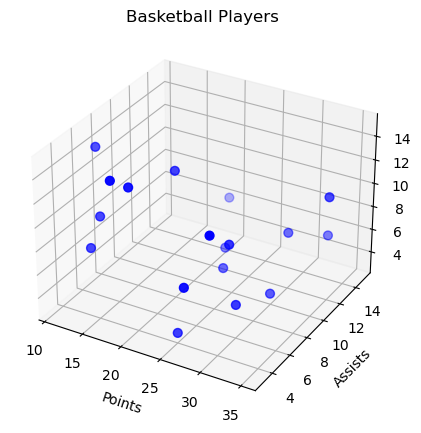

In [6]:
plot_data(X)

# b)

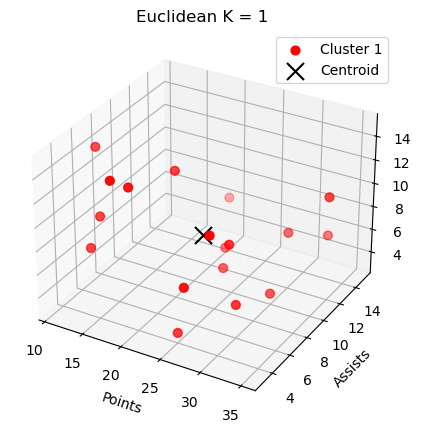

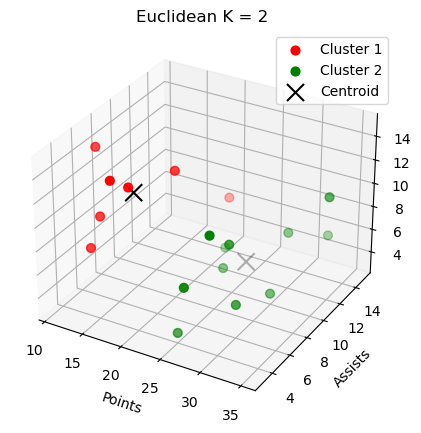

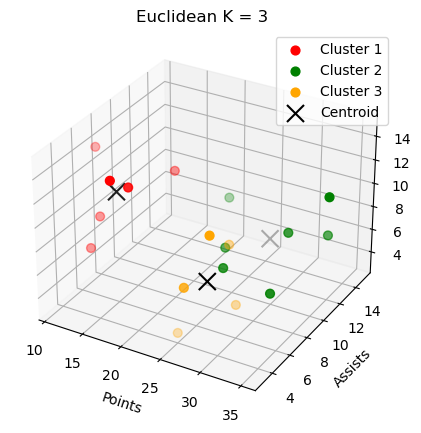

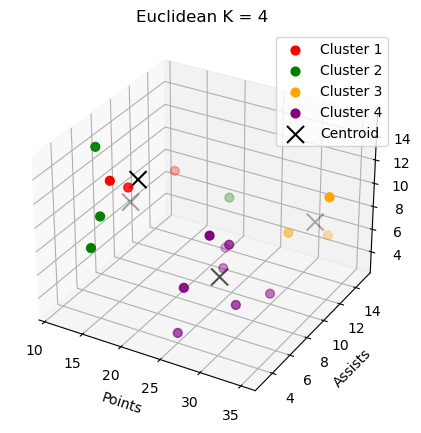

In [7]:
ks=[1,2,3,4]
results_euclidean={}

for k in ks:
    labels,centroids,history=kmeans(X,k,euclidean)
    results_euclidean[k]=(labels,centroids,history)
    plot_clusters(X,labels,centroids,k,"Euclidean")

# c)

In [8]:
sse_euclidean=[]

for k in ks:
    labels,centroids,history=results_euclidean[k]

    print("\nK =",k,"(Euclidean)")
    display(sse_table(df,history))

    sse_euclidean.append(sum(history[-1]))

print("\nFinal SSE:")
for k in ks:
    print("K =",k,"SSE =",round(sse_euclidean[k-1],3))


K = 1 (Euclidean)


,Iter 1,Iter 2
P1,0.0,97.417
P2,3.0,66.528
P3,45.0,107.639
P4,66.0,112.306
P5,66.0,196.972
P6,33.0,34.972
P7,152.0,16.972
P8,253.0,52.306
P9,326.0,72.972
P10,386.0,147.194



K = 2 (Euclidean)


,Iter 1,Iter 2,Iter 3
P1,0.0,32.556,27.980
P2,3.0,18.889,19.837
P3,45.0,21.556,10.408
P4,66.0,28.778,24.265
P5,66.0,73.444,36.265
P6,33.0,14.889,17.265
P7,78.0,10.790,6.909
P8,97.0,16.012,10.091
P9,74.0,12.568,13.636
P10,0.0,54.346,70.727



K = 3 (Euclidean)


,Iter 1,Iter 2,Iter 3,Iter 4,Iter 5
P1,0.0,15.806,15.806,15.806,15.806
P2,3.0,13.139,13.139,13.139,13.139
P3,45.0,9.472,9.472,9.472,9.472
P4,66.0,24.139,24.139,24.139,24.139
P5,66.0,31.139,31.139,31.139,31.139
P6,33.0,24.472,24.472,24.472,24.472
P7,0.0,8.843,12.500,13.889,7.440
P8,21.0,18.388,22.100,21.556,12.040
P9,38.0,17.570,17.100,16.111,21.592
P10,78.0,69.207,65.300,68.778,71.306



K = 4 (Euclidean)


,Iter 1,Iter 2
P1,0.0,6.000
P2,3.0,1.000
P3,29.0,8.062
P4,54.0,16.562
P5,0.0,33.062
P6,33.0,11.000
P7,18.0,7.594
P8,27.0,9.844
P9,68.0,25.344
P10,0.0,14.889



Final SSE:
K = 1 SSE = 1347.5
K = 2 SSE = 597.143
K = 3 SSE = 457.824
K = 4 SSE = 365.333


# d)

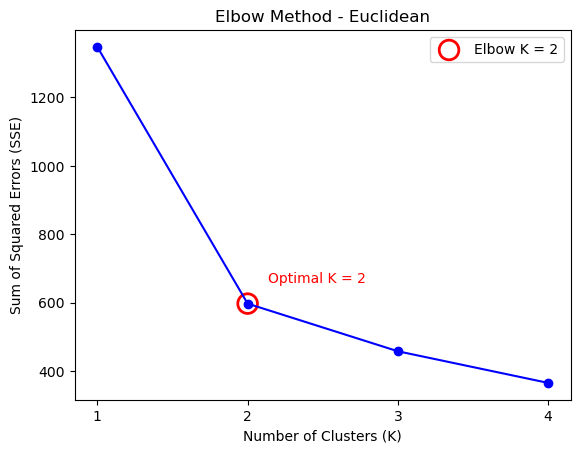

Optimal K (Euclidean): 2


In [36]:
best_euclidean=elbow_k(ks,sse_euclidean)

plot_elbow(ks,sse_euclidean,best_euclidean,"Euclidean")

print("Optimal K (Euclidean):",best_euclidean)

# Q2 a)

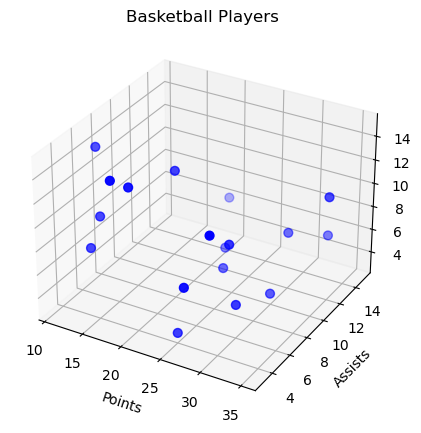

In [10]:
plot_data(X)

# b)

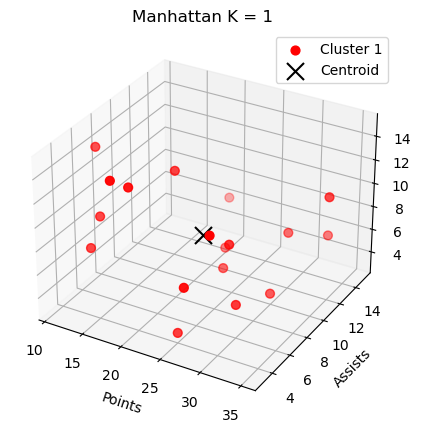

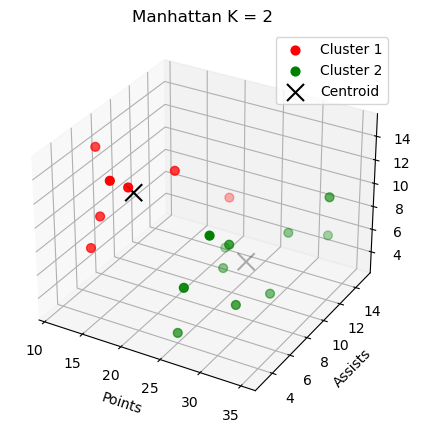

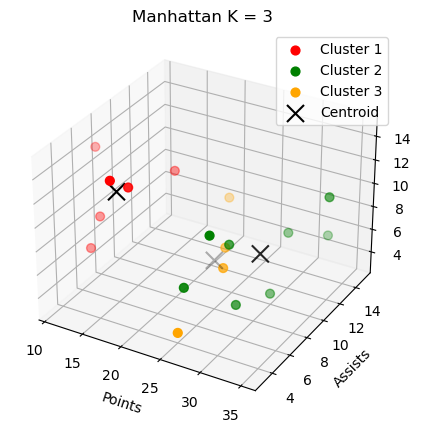

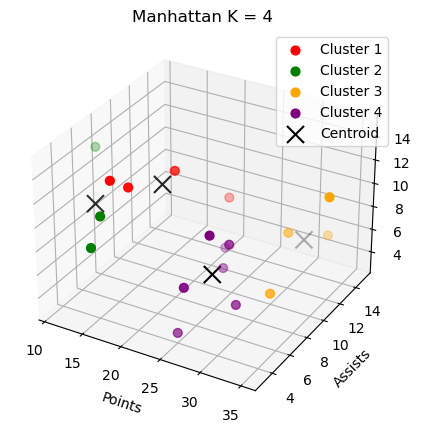

In [11]:
ks=[1,2,3,4]
results_manhattan={}

for k in ks:
    labels,centroids,history=kmeans(X,k,manhattan)
    results_manhattan[k]=(labels,centroids,history)
    plot_clusters(X,labels,centroids,k,"Manhattan")

# c)

In [12]:
sse_manhattan=[]

for k in ks:
    labels,centroids,history=results_manhattan[k]

    print("\nK =",k,"(Manhattan)")
    display(sse_table(df,history))

    sse_manhattan.append(sum(history[-1]))

print("\nFinal SSE:")
for k in ks:
    print("K =",k,"SSE =",round(sse_manhattan[k-1],3))


K = 1 (Manhattan)


,Iter 1,Iter 2
P1,0.0,287.114
P2,9.0,194.448
P3,121.0,194.448
P4,144.0,200.694
P5,144.0,358.892
P6,81.0,76.077
P7,400.0,25.559
P8,625.0,127.188
P9,900.0,170.448
P10,900.0,318.028



K = 2 (Manhattan)


,Iter 1,Iter 2,Iter 3
P1,0.0,81.000,75.939
P2,9.0,36.000,59.510
P3,121.0,43.560,29.469
P4,144.0,92.160,71.041
P5,144.0,184.960,71.041
P6,81.0,29.160,43.184
P7,196.0,47.266,17.488
P8,289.0,37.516,28.769
P9,196.0,26.266,33.851
P10,0.0,147.016,201.124



K = 3 (Manhattan)


,Iter 1,Iter 2,Iter 3
P1,0.0,46.694,46.694
P2,9.0,34.028,34.028
P3,121.0,20.250,20.250
P4,144.0,56.250,56.250
P5,144.0,72.250,72.250
P6,81.0,56.250,56.250
P7,0.0,21.778,25.000
P8,49.0,42.975,30.250
P9,100.0,30.864,25.000
P10,196.0,149.383,132.250



K = 4 (Manhattan)


,Iter 1,Iter 2,Iter 3
P1,0.0,57.760,72.250
P2,9.0,43.560,30.250
P3,81.0,20.250,4.000
P4,144.0,56.250,25.000
P5,0.0,20.250,49.000
P6,81.0,25.000,6.250
P7,36.0,18.367,18.367
P8,81.0,27.939,27.939
P9,196.0,49.000,49.000
P10,0.0,49.000,49.000



Final SSE:
K = 1 SSE = 3066.846
K = 2 SSE = 1491.305
K = 3 SSE = 1013.535
K = 4 SSE = 856.434


# d)

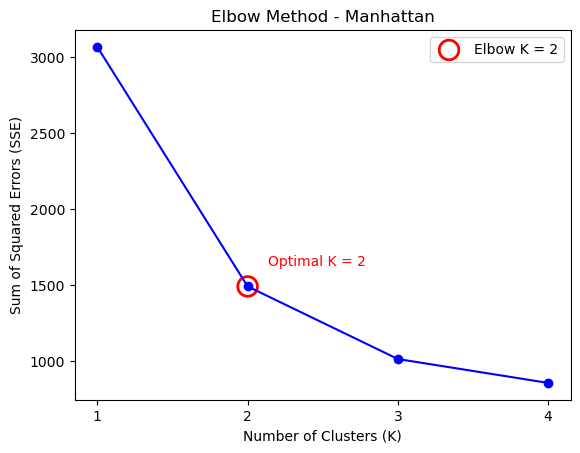

Optimal K (Manhattan): 2


In [35]:
best_manhattan=elbow_k(ks,sse_manhattan)

plot_elbow(ks,sse_manhattan,best_manhattan,"Manhattan")

print("Optimal K (Manhattan):",best_manhattan)

# Q3 a)

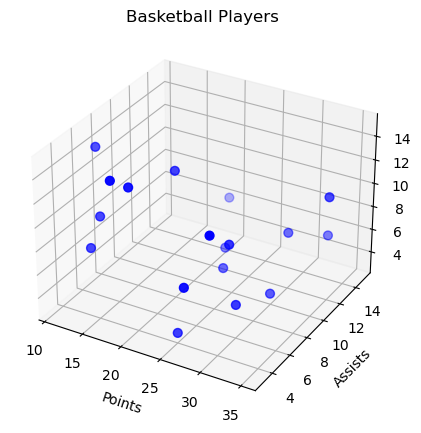

In [14]:
plot_data(X)

# b)

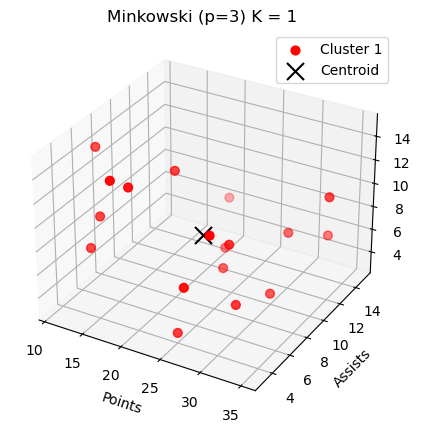

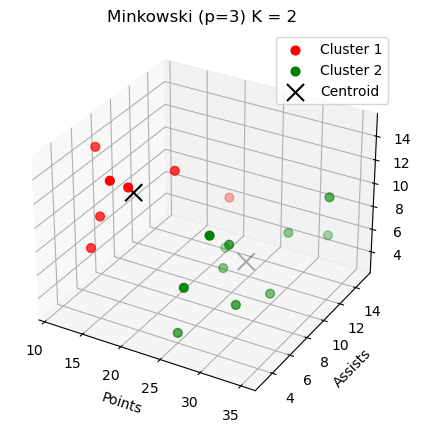

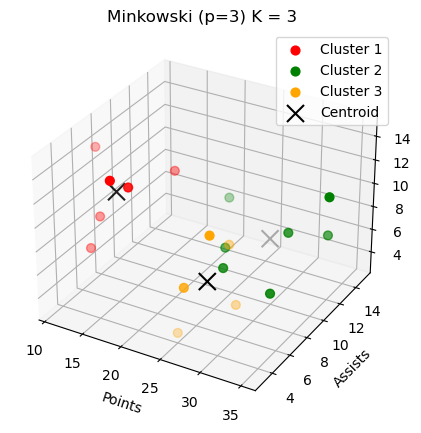

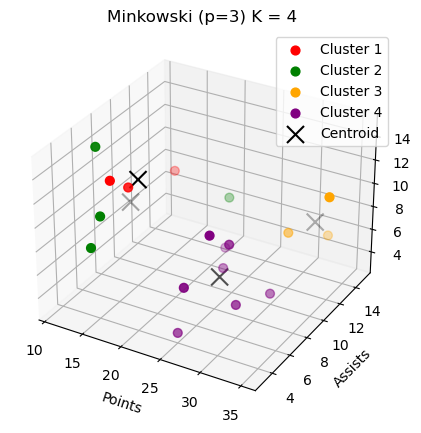

In [15]:
ks=[1,2,3,4]
results_minkowski={}

for k in ks:
    labels,centroids,history=kmeans(X,k,minkowski)
    results_minkowski[k]=(labels,centroids,history)
    plot_clusters(X,labels,centroids,k,"Minkowski (p=3)")

# c)

In [16]:
sse_minkowski=[]

for k in ks:
    labels,centroids,history=results_minkowski[k]

    print("\nK =",k,"(Minkowski (p=3))")
    display(sse_table(df,history))

    sse_minkowski.append(sum(history[-1]))

print("\nFinal SSE:")
for k in ks:
    print("K =",k,"SSE =",round(sse_minkowski[k-1],3))


K = 1 (Minkowski (p=3))


,Iter 1,Iter 2
P1,0.000,68.656
P2,2.080,47.218
P3,33.857,100.260
P4,55.010,102.039
P5,55.010,175.536
P6,27.090,27.723
P7,117.889,16.495
P8,196.523,42.117
P9,241.115,58.893
P10,319.316,128.076



K = 2 (Minkowski (p=3))


,Iter 1,Iter 2,Iter 3
P1,0.000,28.352,20.818
P2,2.080,16.751,13.754
P3,33.857,19.489,7.641
P4,55.010,23.378,17.248
P5,55.010,58.174,31.531
P6,27.090,8.768,13.994
P7,60.964,6.595,5.481
P8,67.697,8.208,7.322
P9,57.323,9.047,10.599
P10,0.000,41.953,51.699



K = 3 (Minkowski (p=3))


,Iter 1,Iter 2,Iter 3,Iter 4,Iter 5
P1,0.000,11.131,11.131,11.131,11.131
P2,2.080,10.333,10.333,10.333,10.333
P3,33.857,7.541,7.541,7.541,7.541
P4,55.010,20.225,20.225,20.225,20.225
P5,55.010,26.419,26.419,26.419,26.419
P6,27.090,19.640,19.640,19.640,19.640
P7,0.000,7.046,10.167,11.775,6.015
P8,17.467,13.609,17.344,15.098,8.821
P9,29.472,13.920,13.100,11.658,15.145
P10,60.964,54.015,51.912,55.092,58.531



K = 4 (Minkowski (p=3))


,Iter 1,Iter 2
P1,0.000,4.642
P2,2.080,1.000
P3,21.400,7.623
P4,41.774,14.678
P5,0.000,26.241
P6,27.090,9.439
P7,16.332,7.011
P8,18.721,8.237
P9,49.095,18.493
P10,0.000,11.696



Final SSE:
K = 1 SSE = 1112.276
K = 2 SSE = 468.291
K = 3 SSE = 384.47
K = 4 SSE = 289.383


# d)

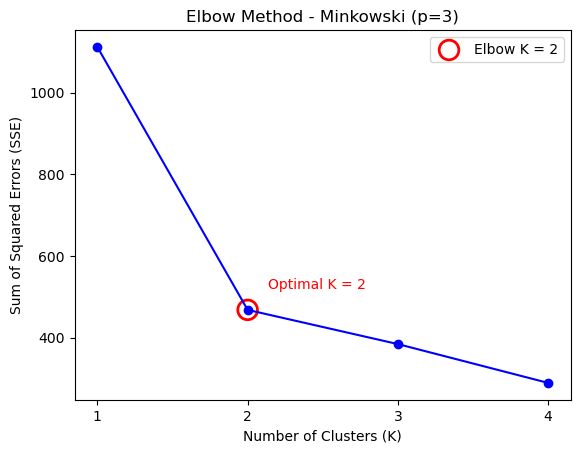

Optimal K (Minkowski (p=3)): 2


In [34]:
best_minkowski=elbow_k(ks,sse_minkowski)

plot_elbow(ks,sse_minkowski,best_minkowski,"Minkowski (p=3)")

print("Optimal K (Minkowski (p=3)):",best_minkowski)

# Additional Q1 (with scikit-learn) Dataset

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances

df=create_dataframe()
X=df.values.astype(float)

print(df)

     points  assists  rebounds
P1       18        3        15
P2       19        4        14
P3       14        5        10
P4       14        4         8
P5       11        7        14
P6       20        8        13
P7       28        7         9
P8       30        6         5
P9       31        9         4
P10      35       12        11
P11      33       14         6
P12      25        9         5
P13      25        4         3
P14      27        3         8
P15      29        4        12
P16      30       12         7
P17      19       15         6
P18      23       11         5


In [19]:
def sk_initial(X,k):
    n=len(X)
    return np.array([X[int(i*n/k)] for i in range(k)])


def sk_kmeans_euclidean(X,k):

    km=KMeans(n_clusters=k,init=sk_initial(X,k),n_init=1)
    km.fit(X)

    history=[]

    for it in range(1,km.n_iter_+1):
        step=KMeans(n_clusters=k,init=sk_initial(X,k),n_init=1,max_iter=it)
        step.fit(X)
        history.append(list(np.min(step.transform(X),axis=1)**2))

    return list(km.labels_),km.cluster_centers_,history


def sk_kmeans_metric(X,k,metric,p=3,max_iter=100):

    centroids=sk_initial(X,k)
    history=[]

    for it in range(max_iter):

        if metric=="minkowski":
            d=pairwise_distances(X,centroids,metric=metric,p=p)
        else:
            d=pairwise_distances(X,centroids,metric=metric)

        labels=np.argmin(d,axis=1)
        history.append(list(np.min(d,axis=1)**2))

        new_centroids=np.array([X[labels==j].mean(axis=0) if np.any(labels==j) else centroids[j] for j in range(k)])

        if np.allclose(new_centroids,centroids):
            break

        centroids=new_centroids

    return list(labels),centroids,history

# Additional Q1 a)

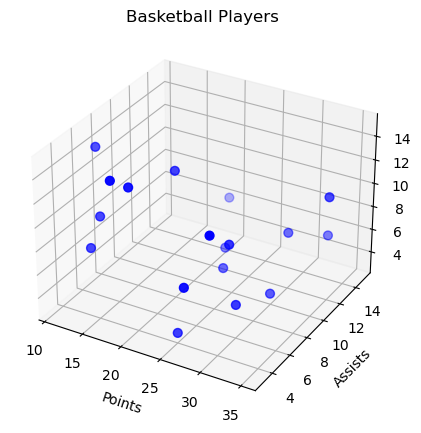

In [20]:
plot_data(X)

# b)

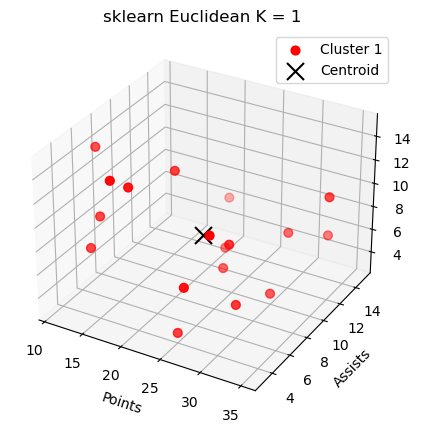

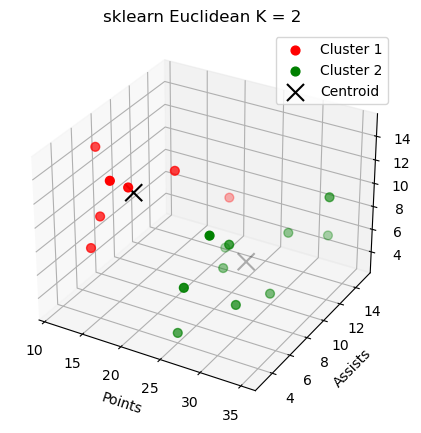

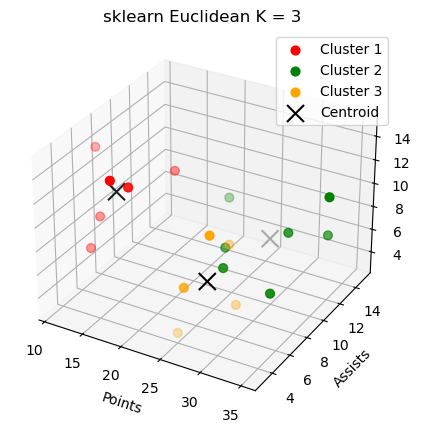

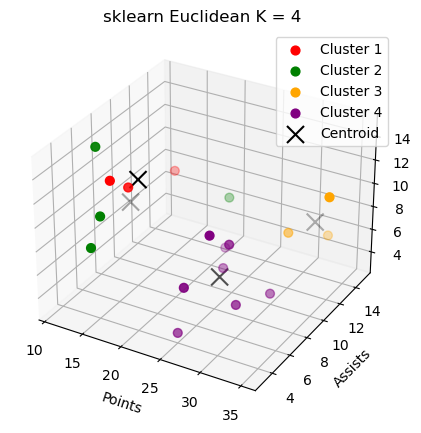

In [21]:
ks=[1,2,3,4]
results_sk_euc={}

for k in ks:
    labels,centroids,history=sk_kmeans_euclidean(X,k)
    results_sk_euc[k]=(labels,centroids,history)
    plot_clusters(X,labels,centroids,k,"sklearn Euclidean")

# c)

In [22]:
sse_sk_euc=[]

for k in ks:
    labels,centroids,history=results_sk_euc[k]

    print("\nK =",k,"(sklearn Euclidean)")
    display(sse_table(df,history))

    sse_sk_euc.append(sum(history[-1]))

print("\nFinal SSE:")
for k in ks:
    print("K =",k,"SSE =",round(sse_sk_euc[k-1],3))


K = 1 (sklearn Euclidean)


,Iter 1,Iter 2
P1,97.417,97.417
P2,66.528,66.528
P3,107.639,107.639
P4,112.306,112.306
P5,196.972,196.972
P6,34.972,34.972
P7,16.972,16.972
P8,52.306,52.306
P9,72.972,72.972
P10,147.194,147.194



K = 2 (sklearn Euclidean)


,Iter 1,Iter 2,Iter 3
P1,32.556,27.980,27.980
P2,18.889,19.837,19.837
P3,21.556,10.408,10.408
P4,28.778,24.265,24.265
P5,73.444,36.265,36.265
P6,14.889,17.265,17.265
P7,10.790,6.909,6.909
P8,16.012,10.091,10.091
P9,12.568,13.636,13.636
P10,54.346,70.727,70.727



K = 3 (sklearn Euclidean)


,Iter 1,Iter 2,Iter 3,Iter 4,Iter 5
P1,15.806,15.806,15.806,15.806,15.806
P2,13.139,13.139,13.139,13.139,13.139
P3,9.472,9.472,9.472,9.472,9.472
P4,24.139,24.139,24.139,24.139,24.139
P5,31.139,31.139,31.139,31.139,31.139
P6,24.472,24.472,24.472,24.472,24.472
P7,8.843,12.500,13.889,7.440,7.440
P8,18.388,22.100,21.556,12.040,12.040
P9,17.570,17.100,16.111,21.592,21.592
P10,69.207,65.300,68.778,71.306,71.306



K = 4 (sklearn Euclidean)


,Iter 1,Iter 2
P1,6.000,6.000
P2,1.000,1.000
P3,8.062,8.062
P4,16.562,16.562
P5,33.062,33.062
P6,11.000,11.000
P7,7.594,7.594
P8,9.844,9.844
P9,25.344,25.344
P10,14.889,14.889



Final SSE:
K = 1 SSE = 1347.5
K = 2 SSE = 597.143
K = 3 SSE = 457.824
K = 4 SSE = 365.333


# d)

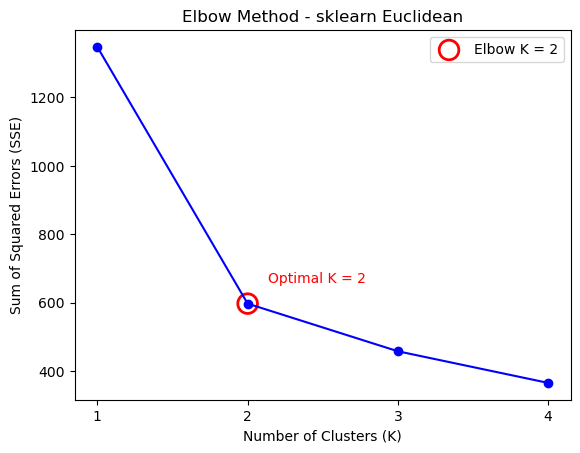

Optimal K (sklearn Euclidean): 2


In [33]:
best_sk_euc=elbow_k(ks,sse_sk_euc)

plot_elbow(ks,sse_sk_euc,best_sk_euc,"sklearn Euclidean")

print("Optimal K (sklearn Euclidean):",best_sk_euc)

# Additional Q2 a)

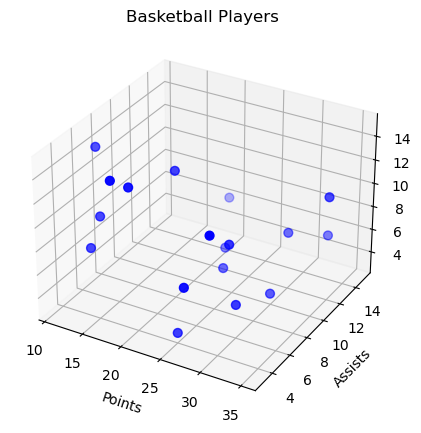

In [24]:
plot_data(X)

# b)

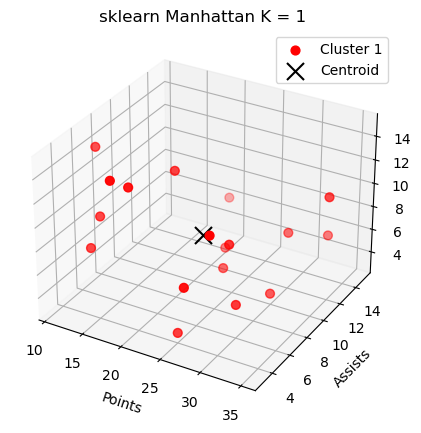

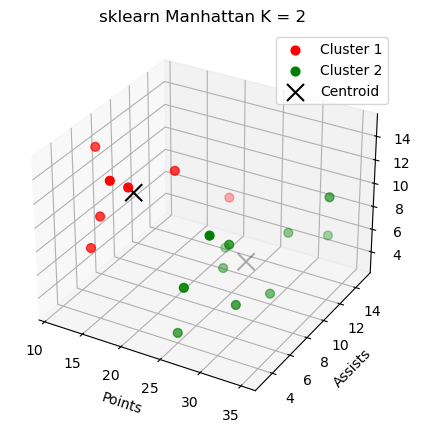

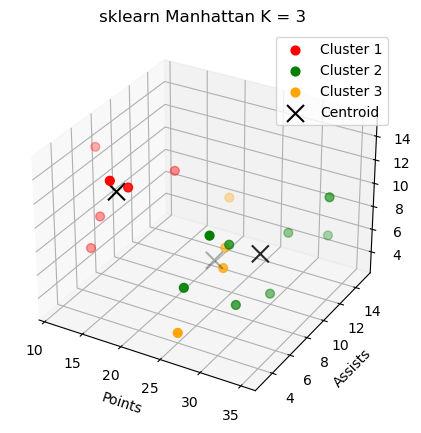

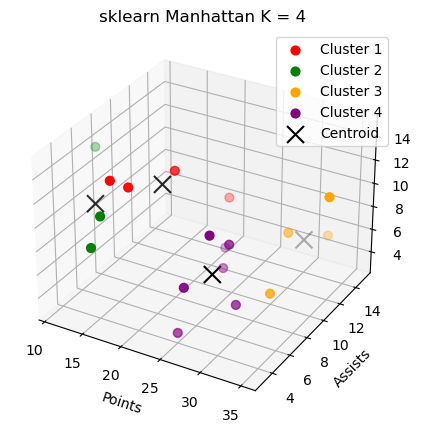

In [25]:
ks=[1,2,3,4]
results_sk_man={}

for k in ks:
    labels,centroids,history=sk_kmeans_metric(X,k,"manhattan")
    results_sk_man[k]=(labels,centroids,history)
    plot_clusters(X,labels,centroids,k,"sklearn Manhattan")

# c)

In [26]:
sse_sk_man=[]

for k in ks:
    labels,centroids,history=results_sk_man[k]

    print("\nK =",k,"(sklearn Manhattan)")
    display(sse_table(df,history))

    sse_sk_man.append(sum(history[-1]))

print("\nFinal SSE:")
for k in ks:
    print("K =",k,"SSE =",round(sse_sk_man[k-1],3))


K = 1 (sklearn Manhattan)


,Iter 1,Iter 2
P1,0.0,287.114
P2,9.0,194.448
P3,121.0,194.448
P4,144.0,200.694
P5,144.0,358.892
P6,81.0,76.077
P7,400.0,25.559
P8,625.0,127.188
P9,900.0,170.448
P10,900.0,318.028



K = 2 (sklearn Manhattan)


,Iter 1,Iter 2,Iter 3
P1,0.0,81.000,75.939
P2,9.0,36.000,59.510
P3,121.0,43.560,29.469
P4,144.0,92.160,71.041
P5,144.0,184.960,71.041
P6,81.0,29.160,43.184
P7,196.0,47.266,17.488
P8,289.0,37.516,28.769
P9,196.0,26.266,33.851
P10,0.0,147.016,201.124



K = 3 (sklearn Manhattan)


,Iter 1,Iter 2,Iter 3
P1,0.0,46.694,46.694
P2,9.0,34.028,34.028
P3,121.0,20.250,20.250
P4,144.0,56.250,56.250
P5,144.0,72.250,72.250
P6,81.0,56.250,56.250
P7,0.0,21.778,25.000
P8,49.0,42.975,30.250
P9,100.0,30.864,25.000
P10,196.0,149.383,132.250



K = 4 (sklearn Manhattan)


,Iter 1,Iter 2,Iter 3
P1,0.0,57.760,72.250
P2,9.0,43.560,30.250
P3,81.0,20.250,4.000
P4,144.0,56.250,25.000
P5,0.0,20.250,49.000
P6,81.0,25.000,6.250
P7,36.0,18.367,18.367
P8,81.0,27.939,27.939
P9,196.0,49.000,49.000
P10,0.0,49.000,49.000



Final SSE:
K = 1 SSE = 3066.846
K = 2 SSE = 1491.305
K = 3 SSE = 1013.535
K = 4 SSE = 856.434


# d)

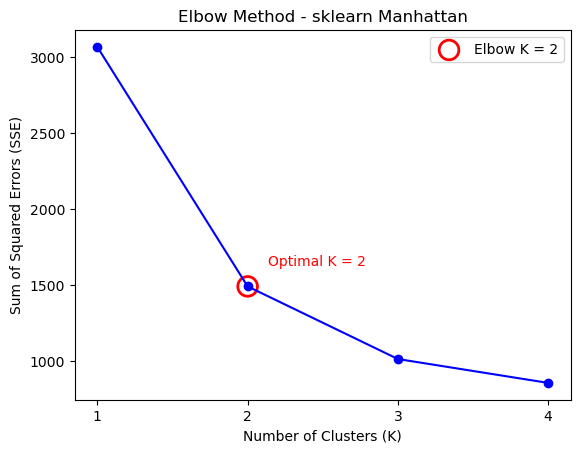

Optimal K (sklearn Manhattan): 2


In [32]:
best_sk_man=elbow_k(ks,sse_sk_man)

plot_elbow(ks,sse_sk_man,best_sk_man,"sklearn Manhattan")

print("Optimal K (sklearn Manhattan):",best_sk_man)

# Additional Q3 a)

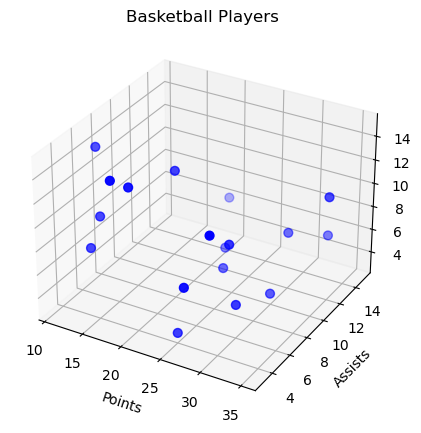

In [28]:
plot_data(X)

# b)

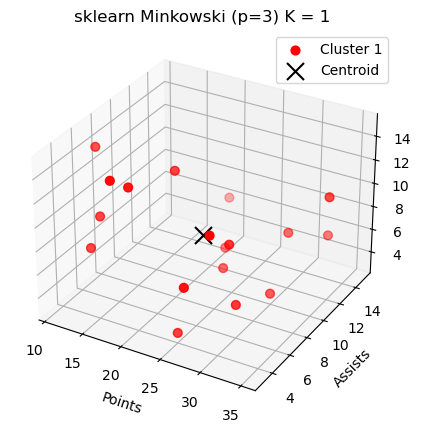

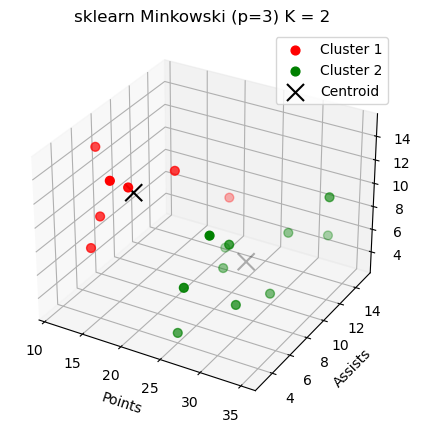

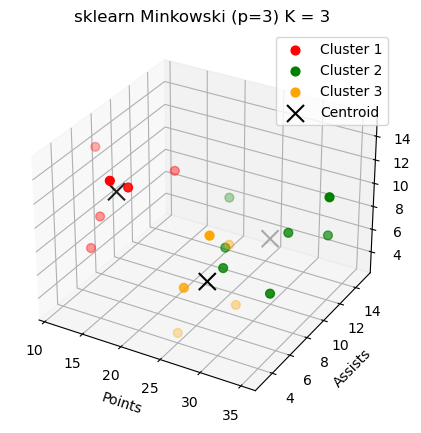

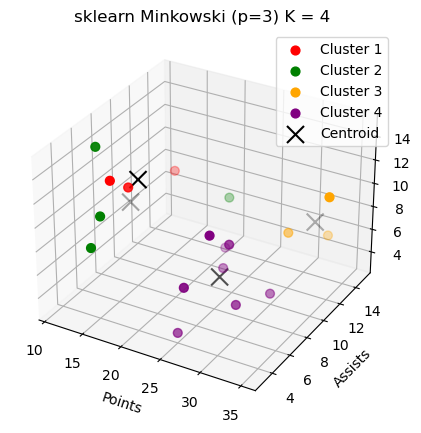

In [29]:
ks=[1,2,3,4]
results_sk_min={}

for k in ks:
    labels,centroids,history=sk_kmeans_metric(X,k,"minkowski",p=3)
    results_sk_min[k]=(labels,centroids,history)
    plot_clusters(X,labels,centroids,k,"sklearn Minkowski (p=3)")

# c)

In [30]:
sse_sk_min=[]

for k in ks:
    labels,centroids,history=results_sk_min[k]

    print("\nK =",k,"(sklearn Minkowski (p=3))")
    display(sse_table(df,history))

    sse_sk_min.append(sum(history[-1]))

print("\nFinal SSE:")
for k in ks:
    print("K =",k,"SSE =",round(sse_sk_min[k-1],3))


K = 1 (sklearn Minkowski (p=3))


,Iter 1,Iter 2
P1,0.000,68.656
P2,2.080,47.218
P3,33.857,100.260
P4,55.010,102.039
P5,55.010,175.536
P6,27.090,27.723
P7,117.889,16.495
P8,196.523,42.117
P9,241.115,58.893
P10,319.316,128.076



K = 2 (sklearn Minkowski (p=3))


,Iter 1,Iter 2,Iter 3
P1,0.000,28.352,20.818
P2,2.080,16.751,13.754
P3,33.857,19.489,7.641
P4,55.010,23.378,17.248
P5,55.010,58.174,31.531
P6,27.090,8.768,13.994
P7,60.964,6.595,5.481
P8,67.697,8.208,7.322
P9,57.323,9.047,10.599
P10,0.000,41.953,51.699



K = 3 (sklearn Minkowski (p=3))


,Iter 1,Iter 2,Iter 3,Iter 4,Iter 5
P1,0.000,11.131,11.131,11.131,11.131
P2,2.080,10.333,10.333,10.333,10.333
P3,33.857,7.541,7.541,7.541,7.541
P4,55.010,20.225,20.225,20.225,20.225
P5,55.010,26.419,26.419,26.419,26.419
P6,27.090,19.640,19.640,19.640,19.640
P7,0.000,7.046,10.167,11.775,6.015
P8,17.467,13.609,17.344,15.098,8.821
P9,29.472,13.920,13.100,11.658,15.145
P10,60.964,54.015,51.912,55.092,58.531



K = 4 (sklearn Minkowski (p=3))


,Iter 1,Iter 2
P1,0.000,4.642
P2,2.080,1.000
P3,21.400,7.623
P4,41.774,14.678
P5,0.000,26.241
P6,27.090,9.439
P7,16.332,7.011
P8,18.721,8.237
P9,49.095,18.493
P10,0.000,11.696



Final SSE:
K = 1 SSE = 1112.276
K = 2 SSE = 468.291
K = 3 SSE = 384.47
K = 4 SSE = 289.383


# d)

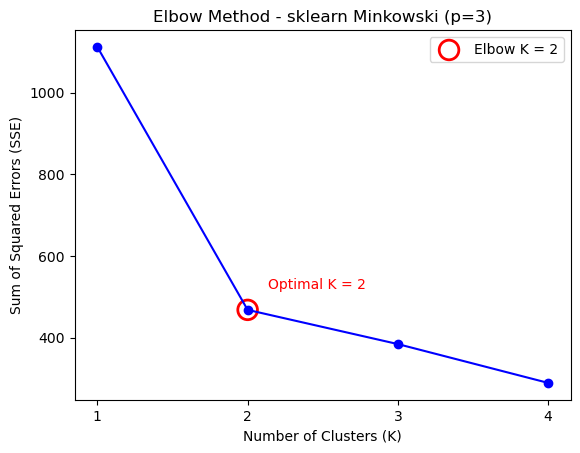

Optimal K (sklearn Minkowski (p=3)): 2


In [31]:
best_sk_min=elbow_k(ks,sse_sk_min)

plot_elbow(ks,sse_sk_min,best_sk_min,"sklearn Minkowski (p=3)")

print("Optimal K (sklearn Minkowski (p=3)):",best_sk_min)